# Gravity Wave Source Parameterization using Deep Learning
This notebook documents the development and evaluation of a machine learning surrogate model for gravity wave soursce parameterization in atmospheric simulations.

## 1. Introduction

Gravity waves (GWs) play an important role in atmospheric dynamics, as they transport momentum and energy from the lower atmosphere up to the mesosphere. However, small-scale gravity waves with horizontal wavelengths ranging from tens to hundreds of kilometers cannot be resolved in general circulation models. As a result, their effects must be parameterized. Gravity-wave parameterization can generally be divided into four components: emission, propagation, dissipation, and the resulting impact on the resolved flow.

GW emission can be categorized into three main source types: orography, convection, and dynamical weather systems such as jets and fronts. Among these sources, orographic gravity waves are the most well-established and understood. Recent developments include the local spectral decomposition of subgrid-scale orography, making parameterizations more resolution-aware. Convective gravity-wave emission is typically represented using heating profiles derived from convection parameterization schemes in general circulation models (GCMs). In contrast, for gravity waves generated by jets, fronts, and other dynamical weather systems, no physically based flow-dependent parameterizations currently exist. Instead, large-scale models generally rely on simplified source representations that are often seasonally dependent and zonally symmetric, introducing uncertainties in momentum transport and the resulting general circulation.

In this study, we address this limitation by developing a data-driven framework to parameterize gravity-wave emission from resolved atmospheric conditions. High-resolution simulations are used to provide representations of gravity-wave activity associated with these dynamical systems. Machine learning (ML) is then employed to learn the nonlinear mapping between the large-scale atmospheric state and the resulting gravity-wave response.

Finally, a explainable artificial intelligence (XAI) method is used to interpret the learned model and quantify the relative importance of different physical predictors.

## 2. Problem Formulation

To parameterize gravity wave (GW) emission, we aim to train a deep neural network that learns a mapping from resolved atmospheric variables to a wave action density spectrum in wavenumber space. The spectrum spans vertical wavelengths from 2 km to 18 km and horizontal wavelengths around 50–90 km at an altitude of 15 km.

The wave action density spectrum is derived from ICON high-resolution simulations (described in the next section).

The input variables include wind fields U, V, W (m/s), pressure p, temperature T, Brunt–Väisälä frequency N, buoyancy b, Reynolds stress term $\overline{T'w'}$, spatial gradients $\nabla_x, \nabla_y (U, V, T)$, and vorticity at six vertical levels between 5 km and 15 km.

To account for orographic features over land, nine additional features are constructed using Fourier analysis of high-resolution subgrid-scale orography.

These include:

- Variance:
  $\sum H_{\text{spec}}^2$, which describes the overall amplitude of orographic features and directly controls gravity wave emission (flux ∝ $H_{\text{spec}}^2$).

- Mean wavenumbers:
  $\bar{k} = \frac{\sum k H_{\text{spec}}}{\sum H_{\text{spec}}}$,
  $\bar{l} = \frac{\sum l H_{\text{spec}}}{\sum H_{\text{spec}}}$.

- Dominant wave length measures:
  $ridge\_oro\_k = \frac{\sum H_{\text{spec}} \cdot (1/k)}{\sum H_{\text{spec}}^2}$,
  $ridge\_oro\_l = \frac{\sum H_{\text{spec}} \cdot (1/l)}{\sum H_{\text{spec}}^2}$.

- Spectral width:
  $var_k = \frac{\sum H_{\text{spec}} (k - \bar{k})^2}{\sum H_{\text{spec}}}$,
  $var_l = \frac{\sum H_{\text{spec}} (l - \bar{l})^2}{\sum H_{\text{spec}}}$.

- Anisotropy:
  $\frac{\sum H_{\text{spec}} k}{\sum H_{\text{spec}} l}$.

- Orientation:
  $\arctan(\bar{k} / \bar{l})$.

## 3. Data

The dataset used in this study is derived from high-resolution ICON simulations with a horizontal resolution of 2.5 km (R2B10), covering the period from 23–30 January. The prognostic variables (u, v, w, p, T) are stored at 10-minute intervals and at six vertical levels given by:

[15113.594, 13021.524, 11021.524, 9021.524, 7021.524, 5033.731] m.

### 3.1 Gravity Wave Spectrum Construction

To construct the target gravity wave (GW) source representation, we follow a multi-step spectral reconstruction approach. First, the high-resolution atmospheric fields are aggregated onto coarser triangular cells with a characteristic horizontal resolution of approximately 160 km (R2B04), which represents the target scale for parameterization.

Spatial Fourier coefficients are computed within each coarse cell using a least-squares Fourier fitting (LSFF) approach:

(F^T F + λI) f̂ = F f.

A temporal Fourier transform is then applied to the obtained coefficients using a 24-hour sliding window. For computational efficiency, the triangular cells are grouped into 10 latitude bands, and the spectra are interpolated onto a unified wavenumber space.

To isolate gravity wave signals, only spectral components satisfying the intrinsic frequency condition

f² < ω̂² < N²

are retained.

A modal decomposition is then performed using the dispersion relation to compute vertical wavenumbers. The state vector

X = (ũ, ṽ, w̃, p̃, b̃)

is projected onto the gravity wave polarization vector Y, yielding:

X_proj = ((X, Y) / (Y, Y)) Y.

Finally, the wave-action density is transformed from (k, l, ω) space into (k, l, m) space using appropriate Jacobian transformations:

𝒩(k, l, m) = 𝒩(k, l, ω) · c_gz,

and subsequently interpolated onto a regular wavenumber grid.

### 3.2 Dimensionality and Coarse-Graining

The resulting wave-action spectrum consists of approximately 2100 spectral bins and exhibits a strongly heavy-tailed distribution, with values ranging from near-zero amplitudes to magnitudes of order 10⁵. Due to limited training data and computational constraints, direct modeling of the full spectrum is not feasible.

Classical dimensionality reduction methods such as Principal Component Analysis (PCA) require approximately 500 components to capture 90% of the variance, indicating strong nonlinear structure in the data. While autoencoder-based approaches can further reduce dimensionality, they compromise physical interpretability.

Therefore, a physically motivated coarse-graining strategy is adopted. We retain upward-propagating gravity wave components with representative vertical wavelengths of 2 km, 6 km, and 18 km, and horizontal wavelengths of approximately 68 km and 136 km.

### 3.3 Input Variables and Land–Ocean Separation

The input features consist of resolved atmospheric state variables including wind components (u, v, w), pressure (p), temperature (T), buoyancy frequency (N), buoyancy (b), Reynolds stress term (T'w'), spatial gradients of (u, v, T), and vorticity at six vertical levels between 5 km and 15 km. These gradients were computed on the coarse R2B04 triangular mesh using the Green–Gauss method. The resulting gradient estimates provide information on local flow deformation, temperature fronts, and dynamical imbalances that are known to be associated with gravity-wave generation.

To account for surface heterogeneity, the dataset is divided into land and ocean regions. For ocean cells, only the dynamical atmospheric variables (90 features) are used. For land cells, these variables are augmented with 9 additional subgrid-scale orographic features derived from Fourier analysis.

### 3.4 Sample Construction and Data Splitting

Training samples are generated by treating each coarse triangular cell and each time step as an independent sample. A 1-hour sliding window is applied in time, producing a large collection of cell–time pairs for both land and ocean regions. The dataset is subsequently partitioned using a strict temporal split to prevent information leakage between training, validation, and test periods.
| Region | Number of Cells | Training Samples | Validation Samples | Test Samples |
| :--- | :---: | :---: | :---: | :---: |
| **Ocean** | 11,858 | 1,280,664 | 177,870 | 260,870 |
| **Land** | 8,622 | 931,176 | 129,330 | 129,330 |

## 4. Methodology
### 4.1 Neural Network Architecture
A fully connected feed-forward neural network was used to learn the mapping between resolved atmospheric variables and the coarse-grained gravity-wave spectrum.

The network consists of four hidden layers containing 512, 256, 128, and 64 neurons, respectively. Each hidden layer is followed by layer normalization and a ReLU activation function. To reduce overfitting, L2 regularization is applied to the last three hidden layers and dropout layers with rates of 0.20 and 0.05 are included after the second and third hidden layers, respectively.

The output layer is linear and contains 48 neurons corresponding to the 48 coarse-grained spectral bins. Separate networks are trained for land and ocean regions.
| Layer | Units | Activation | Regularization |
| :--- | :--- | :--- | :--- |
| Input | 90 (Ocean) / 99 (Land) | - | - |
| Dense 1 | 512 | ReLU | LayerNorm |
| Dense 2 | 256 | ReLU | LayerNorm + L2 +<br>Dropout(0.2) |
| Dense 3 | 128 | ReLU | LayerNorm + L2 +<br>Dropout(0.05) |
| Dense 4 | 64 | ReLU | LayerNorm + L2 |
| Output | 48 | Linear | - |

### 4.2 preprocessing
The input features exhibit strongly different scales, ranging from approximately 10⁴ (e.g., pressure-related variables) to 10⁻⁶ (e.g., horizontal gradients). To ensure stable and efficient optimization, all input variables are standardized prior to training using z-score normalization:

x' = (x − μ) / σ

where μ and σ are computed from the training dataset only. This prevents variables with large magnitudes from dominating the loss function and improves convergence behavior during optimization.

The output target is a 48-dimensional wave-action density spectrum with a strongly skewed, heavy-tailed distribution, spanning several orders of magnitude (from values close to zero up to approximately 10⁸). To reduce this dynamic range and improve numerical stability during training, a log-transformation is applied:

y' = log(1 + N)

This transformation compresses large values while preserving relative variations at smaller amplitudes, enabling the model to learn both weak and extreme gravity wave events more effectively.

The log-space formulation also makes the outputs suitable for using Mean Absolute Error (MAE) as a loss function, since it reduces the dominance of extreme outliers and leads to a more balanced gradient contribution across spectral bins. After prediction, all results are transformed back to the physical space using the inverse transformation:

N = exp(y') − 1

### 4.3 Training Procedure
The neural network is trained using the Adam optimizer with an initial learning rate of 10⁻⁴. Gradient clipping is applied using a global norm of 1.0 to ensure numerical stability during optimization. The loss function is Mean Absolute Error (MAE), which is particularly suitable for the heavy-tailed distribution of the gravity wave spectrum, as it reduces the influence of extreme outliers.

Training is performed using mini-batch optimization with a batch size of 32. The dataset is implemented using a TensorFlow data pipeline, where the training set is shuffled and both training and validation datasets are repeated to enable efficient epoch-based training.

To improve generalization and stabilize convergence, three callbacks are used: (i) ModelCheckpoint, which stores the best-performing model based on validation MAE; (ii) EarlyStopping, which terminates training if validation MAE does not improve for 10 consecutive epochs; and (iii) ReduceLROnPlateau, which reduces the learning rate by a factor of 0.5 when validation performance stagnates, with a minimum learning rate of 10⁻⁷.

The model is trained for up to 200 epochs, and the best weights based on validation performance are restored automatically. Separate models are trained for land and ocean regions to account for their distinct dynamical regimes and input feature spaces.

### 4.4 Evaluation Metrics

Model performance is evaluated using multiple complementary metrics due to the strongly skewed and heavy-tailed nature of the gravity-wave action density spectrum. Because the target spans several orders of magnitude, no single metric can fully characterize model performance.

The primary training metric is the Mean Absolute Error (MAE) computed in log-transformed space. In addition to the absolute MAE, a variability-normalized metric is used to assess predictability across different spectral bins:

$$Score = 1 - \frac{\text{MAE}}{\sigma}$$

where $\sigma$ denotes the standard deviation of the corresponding spectral bin. This metric measures the prediction error relative to the intrinsic variability of the target and allows meaningful comparison between spectral components with different amplitudes and variances.

To evaluate performance in physical units, all predictions are transformed back to wave-action density space using the inverse transformation

$$N = \exp(y') - 1$$

Model performance in physical space is compared against a training-mean baseline defined as the mean spectrum computed from the training dataset:

$$N_{\text{baseline}} = \langle N_{\text{train}} \rangle$$

This baseline represents the prediction that would be obtained without knowledge of the instantaneous atmospheric state. A skill score is then defined as

$$Skill = 1 - \frac{\text{MAE}_{\text{model}}}{\text{MAE}_{\text{baseline}}}$$

where $\text{MAE}_{\text{model}}$ denotes the neural-network error and $\text{MAE}_{\text{baseline}}$ denotes the error of the training-mean baseline prediction. Positive values indicate improvement over the baseline, while a value of one corresponds to a perfect prediction.

Because gravity-wave emission is highly intermittent, global averages can mask important differences between weak and extreme events. To investigate model performance across different emission regimes, percentile thresholds are computed independently for each spectral bin using the training dataset. The 90th, 95th, and 99th percentiles are subsequently applied to the validation and test datasets, yielding four regimes: 0–90%, 90–95%, 95–99%, and 99–100%. Using thresholds derived exclusively from the training data ensures a consistent definition of extreme events across all data splits and avoids information leakage.

All metrics are first computed independently for each spectral bin and are subsequently averaged across the 48-dimensional output space to obtain summary statistics. In addition, spatial performance is assessed by computing the MAE for each triangular grid cell and averaging over time, allowing regional differences in model skill to be identified.

### 4.5 Model Interpretability (SHAP Analysis)
To interpret the trained neural network model, SHAP (SHapley Additive exPlanations) values were computed using the Kernel SHAP algorithm. Kernel SHAP estimates the contribution of each input feature to the model prediction by approximating Shapley values from cooperative game theory.

Due to the computational cost of Kernel SHAP, explanations were computed for 200 randomly selected samples from the independent test dataset. For each sample, SHAP values were obtained for all 48 output dimensions. Absolute SHAP values were subsequently averaged over samples and output dimensions to obtain a global measure of feature importance:
$$I_j = \langle |\phi_j| \rangle$$
where $\phi_j$ denotes the SHAP value associated with feature $j$.
To investigate the vertical distribution of predictive information, SHAP values were additionally grouped by variable and altitude level.


## 5.Results
### 5.1 Global spectrum statistics (log-space + normalized metrics)
To characterize the climatological structure of the coarse-grained gravity wave (GW) field, we compute the mean GW wave-action density in log space, $\langle \log(1 + N) \rangle$, aggregated over all samples (spatial and temporal) for each spectral bin. The averaging was performed separately for land and ocean regions. 
The resulting mean spectra (Fig. 5.1) show that spectral energy is not uniformly distributed across wavelength bins. The largest mean amplitudes are generally associated with intermediate vertical wavelengths ($\lambda_z = 6$ km) and larger horizontal wavelengths ($\lambda_k = \lambda_l = 136$ km). These scales correspond to smaller horizontal wavenumbers and, therefore, a wave vector that is more strongly aligned with the vertical direction. 
This suggests that the dominant gravity-wave activity in the dataset is associated primarily with vertically propagating waves. In contrast, bins corresponding to $\lambda_z = 18$ km indicate substantially lower mean amplitudes.

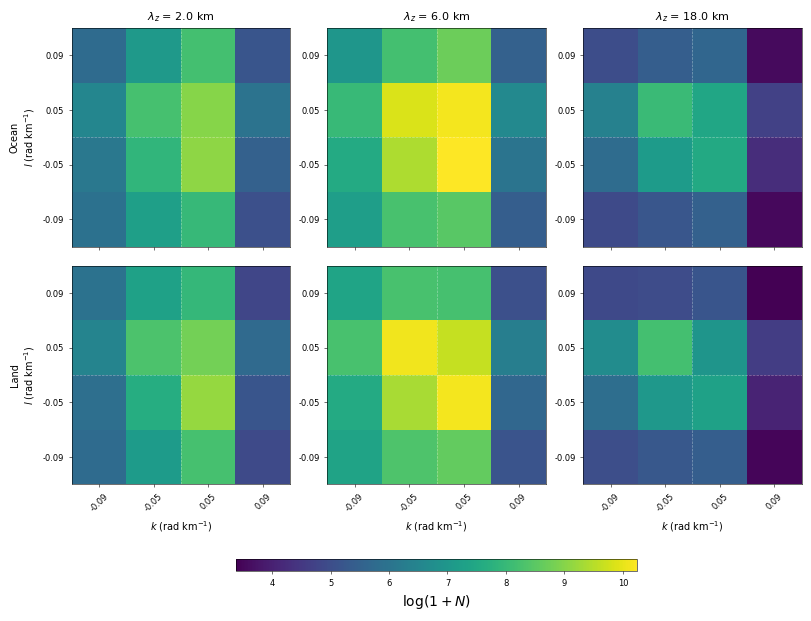

In [2]:
import joblib
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
import xarray as xr
plots_dir = "/work/bb1097/b383521/plots/paper_plots/"
data_dir = "/work/bb1097/b383521/Data_set/"
# ── Load both tags ────────────────────────────────────────────────────────────
N_mean_dict = {}
vmin_global, vmax_global = np.inf, -np.inf

for tag in ["ocean", "land"]:
    fname = f"Data_Base_Time_parttion_coarsedN_{tag}.pkl"
    d = joblib.load(data_dir + fname)
    y_train = np.log1p(d["y_train"])
    N_launch = y_train.reshape(-1, 4, 4, 3)
    N_mean = np.mean(N_launch, axis=0)          # (l, k, m)
    N_mean_dict[tag] = N_mean
    vmin_global = min(vmin_global, N_mean[N_mean > 0].min())
    vmax_global = max(vmax_global, N_mean.max())

# ── Grid (same for both tags) ─────────────────────────────────────────────────
with xr.open_dataset("/work/bb1097/b383521/dummy/coarsed_wave_action_density/"
                     "interp-alt0-fileslide_1-regroup-8.nc") as ds:
    m_coarse = ds.m.data
    l_coarse = ds.l.data
    k_coarse = ds.k.data

k_km = k_coarse * 1e3
l_km = l_coarse * 1e3

n_k, n_l = len(k_km), len(l_km)
uniform_centers_k = np.arange(n_k, dtype=float)
uniform_centers_l = np.arange(n_l, dtype=float)
uniform_edges_k   = np.arange(n_k + 1, dtype=float) - 0.5
uniform_edges_l   = np.arange(n_l + 1, dtype=float) - 0.5
UK_edges, UL_edges = np.meshgrid(uniform_edges_k, uniform_edges_l)

k_zero_idx = np.interp(0, k_km, uniform_centers_k)
l_zero_idx = np.interp(0, l_km, uniform_centers_l)

# ── Figure: 2 rows (ocean, land) × 3 cols (m values) ────────────────────────
fig, axes = plt.subplots(
    2, 3,
    figsize=(8, 6),                  # compact — panels are close together
    constrained_layout=True,
)

row_labels = {"ocean": "Ocean", "land": "Land"}

for irow, tag in enumerate(["ocean", "land"]):
    N_mean = N_mean_dict[tag]
    for im in range(3):
        ax  = axes[irow, im]
        dat = N_mean[:, :, im]
        lz  = 2 * np.pi / np.abs(m_coarse[im]) / 1000

        pcm = ax.pcolormesh(UK_edges, UL_edges, dat,
                            vmin=vmin_global, vmax=vmax_global,
                            cmap='viridis')

        # Title only on top row
        if irow == 0:
            ax.set_title(f"$\\lambda_z$ = {lz:.1f} km", fontsize=8)

        # x-label only on bottom row
        ax.set_xlabel("$k$ (rad km$^{{-1}}$)" if irow == 1 else "",
                      fontsize=7)

        # y-label only on left column; row tag as ylabel
        if im == 0:
            ax.set_ylabel(f"{row_labels[tag]}\n$l$ (rad km$^{{-1}}$)",
                          fontsize=7)
        else:
            ax.set_ylabel("")

        # Ticks: only bottom row gets x tick labels
        ax.set_xticks(uniform_centers_k)
        if irow == 1:
            ax.set_xticklabels([f"{v:.2f}" for v in k_km],
                               rotation=45, fontsize=6)
        else:
            ax.set_xticklabels([])

        ax.set_yticks(uniform_centers_l)
        ax.set_yticklabels([f"{v:.2f}" for v in l_km], fontsize=6)

        ax.axhline(l_zero_idx, color='white', linewidth=0.5,
                   linestyle='--', alpha=0.4)
        ax.axvline(k_zero_idx, color='white', linewidth=0.5,
                   linestyle='--', alpha=0.4)

        ax.set_aspect('equal')
        ax.tick_params(width=0.4, length=2)
        for spine in ax.spines.values():
            spine.set_linewidth(0.4)

# ── Single shared colorbar below all panels ───────────────────────────────────
cbar = fig.colorbar(pcm, ax=axes,
                    label="$\\log(1 + N)$",
                    orientation='horizontal',
                    shrink=0.55, pad=0.05, aspect=35)
cbar.ax.tick_params(labelsize=6, width=0.4, length=2)
cbar.outline.set_linewidth(0.4)

plt.savefig(plots_dir + "launch_spectrum_kl_both.png", dpi=300, bbox_inches='tight')
plt.show()

To analyse the intrinsic predictability of the target spectrum, we compute a mean-to-variability ratio for each spectral bin, indicated in fig 5.2. Larger values show bins where the mean signal exceeds spatial and temporal variability, whereas values close to unity correspond to highly variable components. The largest ratios are observed for the intermediate vertical wavelength bin ($\lambda_z = 6$ km), suggesting that these spectral components represent the most persistent and statistically robust part of the gravity wave spectrum. Conversely, bins with $\lambda_z = 2$ km and $\lambda_z = 18$ km exhibit lower ratios, which indicates increased variability relative to their mean amplitude.

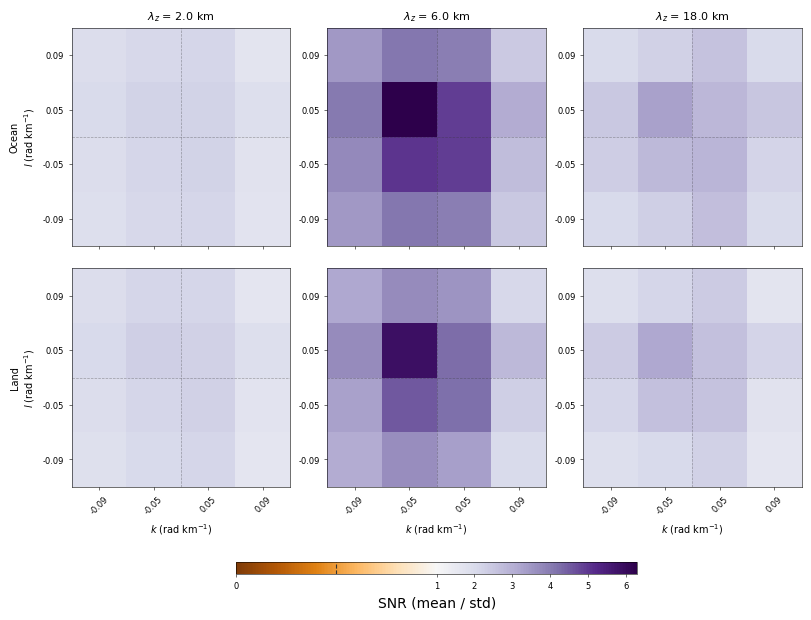

In [4]:
import matplotlib.colors as mcolors

# ── Compute SNR for both tags ─────────────────────────────────────────────────
snr_dict = {}
vmax_snr = -np.inf

for tag in ["ocean", "land"]:
    fname = f"Data_Base_Time_parttion_coarsedN_{tag}.pkl"
    d = joblib.load(data_dir + fname)
    y_train = np.log1p(d["y_train"])
    N_launch = y_train.reshape(-1, 48)
    mean_per_mode = np.nanmean(N_launch, axis=0)
    std_per_mode  = np.nanstd(N_launch,  axis=0)
    snr           = mean_per_mode / std_per_mode
    snr_3d        = snr.reshape(4, 4, 3)        # (l, k, m)
    snr_dict[tag] = snr_3d
    vmax_snr = max(vmax_snr, snr_3d.max())

# Diverging norm: white = SNR 1, blue = high confidence, orange = low
# Using PuOr_r: purple=high SNR, orange=low SNR, white=SNR≈1
# Much more neutral than RdBu — orange reads as "caution" not "danger"
norm = mcolors.TwoSlopeNorm(vmin=0, vcenter=1.0, vmax=vmax_snr)
cmap = plt.get_cmap('PuOr')   # orange=low, white=1, purple=high

# ── Figure: 2 rows × 3 cols ───────────────────────────────────────────────────
fig, axes = plt.subplots(
    2, 3,
    figsize=(8, 6),
    constrained_layout=True,
)

row_labels = {"ocean": "Ocean", "land": "Land"}

for irow, tag in enumerate(["ocean", "land"]):
    snr_3d = snr_dict[tag]
    for im in range(3):
        ax  = axes[irow, im]
        dat = snr_3d[:, :, im]
        lz  = 2 * np.pi / np.abs(m_coarse[im]) / 1000

        pcm = ax.pcolormesh(UK_edges, UL_edges, dat,
                            norm=norm, cmap=cmap)

        # SNR=1 contour in dark gray
        ax.contour(uniform_centers_k, uniform_centers_l, dat,
                   levels=[1.0], colors='#333333',
                   linewidths=0.8, linestyles='--')

        if irow == 0:
            ax.set_title(f"$\\lambda_z$ = {lz:.1f} km", fontsize=8)

        ax.set_xlabel("$k$ (rad km$^{{-1}}$)" if irow == 1 else "",
                      fontsize=7)

        if im == 0:
            ax.set_ylabel(f"{row_labels[tag]}\n$l$ (rad km$^{{-1}}$)",
                          fontsize=7)
        else:
            ax.set_ylabel("")

        ax.set_xticks(uniform_centers_k)
        if irow == 1:
            ax.set_xticklabels([f"{v:.2f}" for v in k_km],
                               rotation=45, fontsize=6)
        else:
            ax.set_xticklabels([])

        ax.set_yticks(uniform_centers_l)
        ax.set_yticklabels([f"{v:.2f}" for v in l_km], fontsize=6)

        ax.axhline(l_zero_idx, color='#333333', linewidth=0.5,
                   linestyle='--', alpha=0.4)
        ax.axvline(k_zero_idx, color='#333333', linewidth=0.5,
                   linestyle='--', alpha=0.4)

        ax.set_aspect('equal')
        ax.tick_params(width=0.4, length=2)
        for spine in ax.spines.values():
            spine.set_linewidth(0.4)

# ── Shared colorbar ───────────────────────────────────────────────────────────
cbar = fig.colorbar(pcm, ax=axes,
                    label="SNR (mean / std)",
                    orientation='horizontal',
                    shrink=0.55, pad=0.05, aspect=35)
cbar.ax.tick_params(labelsize=6, width=0.4, length=2)
cbar.outline.set_linewidth(0.4)
# Mark SNR=1 threshold on colorbar
cbar.ax.axvline(norm(1.0), color='#333333', linewidth=0.8, linestyle='--')

plt.savefig(plots_dir + "snr_per_mode_both.png", dpi=300, bbox_inches='tight')
plt.show()

The neural network indicates consistent predictive skill in log-space for both land and ocean regions. Averaged across the 48 spectral bins, the test-set MAE is 1.23 for land and 1.50 for ocean. Since the target spectrum exhibits substantially different variability across spectral bins, a normalized metric based on the ratio between MAE and the target standard deviation is also considered.

| Region | Split | MAE (log-space) | MAE/std |
| :--- | :--- | :--- | :--- |
| Ocean | Train | 0.892 | 0.353 |
| Ocean | Validation | 1.243 | 0.457 |
| Ocean | Test | 1.495 | 0.538 |
| Land | Train | 0.825 | 0.309 |
| Land | Validation | 1.018 | 0.387 |
| Land | Test | 1.231 | 0.458 |

The normalized error (MAE/std) remains below unity for all datasets, indicating that the typical prediction error is smaller than the intrinsic variability of the target spectrum. On the test set, MAE/std reaches 0.46 over land and 0.54 over ocean, suggesting that the model captures a substantial fraction of the predictable variability. Performance is consistently better over land than over ocean, likely reflecting the additional predictive information provided by the subgrid-scale orographic features used in the land model.
As expected, performance degrades from the training to the validation and test datasets, indicating a finite generalization gap. The increase in normalized error is comparable for both land and ocean models, suggesting moderate overfitting despite the use of regularization, dropout, and early stopping. Nevertheless, the model retains substantial predictive skill on unseen data, with test-set MAE/std remaining below 0.55 for both regions.

To assess the performance of the model for different wave modes, the variability-normalized score ($1 - \text{MAE}/\sigma$) was computed and is exhibited in Fig. 5.3. It ranges from 0.32 to 0.71 across the 48 spectral bins, indicating that the model error is always smaller than the variability of the corresponding target component. Predictability is systematically higher over land than over ocean, with land scores reaching values above 0.70, while the ocean scores mostly remain between approximately 0.35 and 0.62. This suggests that the land model benefits from additional orographic information and that the wave-action spectrum is more constrained over land.

Across both land and ocean, the lowest scores are mostly associated with the shortest vertical wavelength bin, $\lambda_z = 2$ km, whereas the intermediate vertical wavelength bin, $\lambda_z = 6$ km, generally shows higher predictability. This is consistent with the mean spectrum and signal-to-variability analysis, where the $\lambda_z = 6$ km modes exhibited stronger and more stable signals. The result indicates that the model captures the more persistent spectral components more reliably, while short-vertical-wavelength modes remain more difficult to predict.

skill range: 0.319 – 0.709


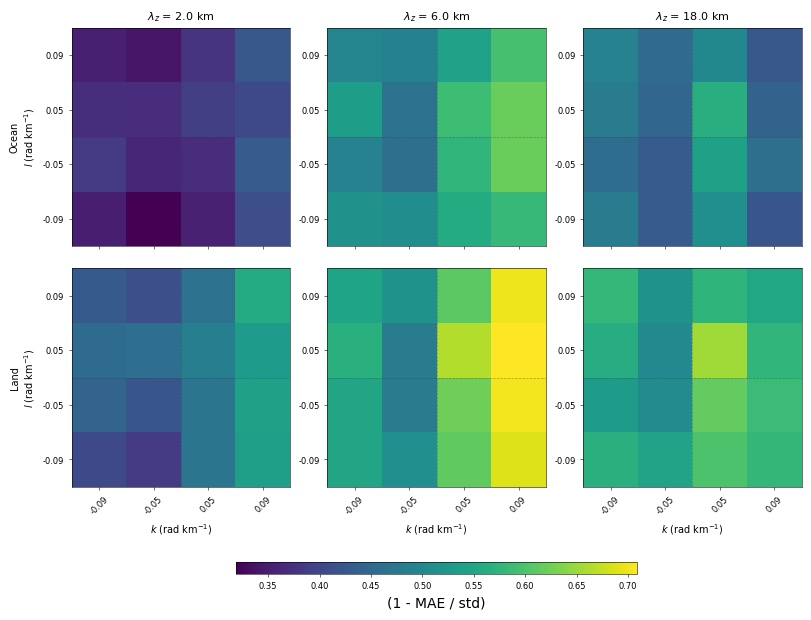

In [5]:
import joblib
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

metrics_dir = "/work/bb1097/b383521/ML_models/coarsed_grained/metrics/"
tags = ["ocean", "land"]

skill_perdim_log = {}

for tag in tags:
    fname   = f"results_{tag}.pkl"
    metrics = joblib.load(metrics_dir + fname)
    skill_perdim_log[tag] = metrics["log_space"]["Test"]["skill"]  # (48,)

# ── Reshape (48,) → (4, 4, 3) = (l, k, m) ───────────────────────────────────
skill_3d = {tag: skill_perdim_log[tag].reshape(4, 4, 3) for tag in tags}

# ── Shared color limits ───────────────────────────────────────────────────────

skill_vmin = min(skill_3d[t].min() for t in tags)
skill_vmax = max(skill_3d[t].max() for t in tags)

print(f"skill range: {skill_vmin:.3f} – {skill_vmax:.3f}")

skill_norm = mcolors.Normalize(vmin=skill_vmin, vmax=skill_vmax)
skill_cmap = plt.get_cmap('Blues')

# ── Uniform grid (same as before) ────────────────────────────────────────────
n_k, n_l = 4, 4
uniform_centers_k = np.arange(n_k, dtype=float)
uniform_centers_l = np.arange(n_l, dtype=float)
uniform_edges_k   = np.arange(n_k + 1, dtype=float) - 0.5
uniform_edges_l   = np.arange(n_l + 1, dtype=float) - 0.5
UK_edges, UL_edges = np.meshgrid(uniform_edges_k, uniform_edges_l)

k_zero_idx = np.interp(0, k_km, uniform_centers_k)
l_zero_idx = np.interp(0, l_km, uniform_centers_l)

row_labels = {"ocean": "Ocean", "land": "Land"}

# ════════════════════════════════════════════════════════════════════════════
# Skill in log space
# ════════════════════════════════════════════════════════════════════════════
fig, axes = plt.subplots(2, 3, figsize=(8, 6), constrained_layout=True)

for irow, tag in enumerate(tags):
    for im in range(3):
        ax  = axes[irow, im]
        dat = skill_3d[tag][:, :, im]
        lz  = 2 * np.pi / np.abs(m_coarse[im]) / 1000

        pcm = ax.pcolormesh(UK_edges, UL_edges, dat,
                            norm=skill_norm, cmap="viridis")

        # skill = 1 contour
        ax.contour(uniform_centers_k, uniform_centers_l, dat,
                   levels=[1.0], colors='#333333',
                   linewidths=0.8, linestyles='--')

        if irow == 0:
            ax.set_title(f"$\\lambda_z$ = {lz:.1f} km", fontsize=8)

        ax.set_xlabel("$k$ (rad km$^{{-1}}$)" if irow == 1 else "", fontsize=7)

        if im == 0:
            ax.set_ylabel(f"{row_labels[tag]}\n$l$ (rad km$^{{-1}}$)", fontsize=7)
        else:
            ax.set_ylabel("")

        ax.set_xticks(uniform_centers_k)
        if irow == 1:
            ax.set_xticklabels([f"{v:.2f}" for v in k_km], rotation=45, fontsize=6)
        else:
            ax.set_xticklabels([])

        ax.set_yticks(uniform_centers_l)
        ax.set_yticklabels([f"{v:.2f}" for v in l_km], fontsize=6)

        ax.axhline(l_zero_idx, color='#333333', linewidth=0.5, linestyle='--', alpha=0.4)
        ax.axvline(k_zero_idx, color='#333333', linewidth=0.5, linestyle='--', alpha=0.4)

        ax.set_aspect('equal')
        ax.tick_params(width=0.4, length=2)
        for spine in ax.spines.values():
            spine.set_linewidth(0.4)

cbar = fig.colorbar(pcm, ax=axes,
                    label="(1 - MAE / std)",
                    orientation='horizontal', shrink=0.55, pad=0.05, aspect=35)
cbar.ax.tick_params(labelsize=6, width=0.4, length=2)
cbar.outline.set_linewidth(0.4)
cbar.ax.axvline(skill_norm(1.0), color='#333333', linewidth=0.8, linestyle='--')

plt.savefig("skill_logspace_both.png", dpi=300, bbox_inches='tight')
plt.show()

### 5.2 Metrics in real space and statistics in differen regimes
After transforming predictions back to physical units, the neural network remains more skillful than the training-mean baseline. Test-set skill scores reach 0.42 over ocean and 0.43 over land, corresponding to approximately 42–43% reductions in MAE relative to a baseline prediction obtained from the mean spectrum of the training dataset. Although performance degrades relative to the training dataset, positive skill is maintained across all data splits, indicating that the model successfully extracts flow-dependent information from the resolved atmospheric state. The slightly higher skill over land suggests that the additional subgrid-scale orographic features provide useful predictive information beyond the resolved flow variables alone.
| Region | Split | MAE | Skill |
| :--- | :--- | :--- | :--- |
| Ocean | Train | 19,143 | 0.511 |
| Ocean | Validation | 20,339 | 0.465 |
| Ocean | Test | 21,456 | 0.420 |
| Land | Train | 25,281 | 0.530 |
| Land | Validation | 31,289 | 0.462 |
| Land | Test | 32,020 | 0.432 |

Because gravity-wave emission exhibits a strongly intermittent and heavy-tailed distribution, global performance metrics alone may obscure important differences between weak and extreme events. To assess model performance across different emission strengths, the dataset was divided into four regimes using percentile thresholds derived from the training data: 0–90%, 90–95%, 95–99%, and 99–100%.

The table below summarizes the test-set skill and MAE for both land and ocean regions.

The highest skill is obtained within the bulk of the distribution (0–90th percentile), where test skill reaches approximately 0.64 over land and 0.61 over ocean. This indicates that the neural network successfully captures the dominant variability of gravity-wave emission under typical atmospheric conditions.

Model performance decreases substantially for increasingly rare events. Within the 90–95% and 95–99% regimes, test skill drops to values between approximately 0.17 and 0.29. The lowest performance is observed for the most extreme 1% of events, where skill decreases to approximately 0.12 over land and 0.10 over ocean. Nevertheless, positive skill is maintained across all regimes, demonstrating that the model consistently outperforms the training-mean baseline even for the strongest gravity-wave emission events.

The reduction in skill toward the distribution tail is accompanied by a rapid increase in absolute error. Mean absolute errors increase from roughly $10^4$ within the bulk regime to approximately $10^6$ for the most extreme events. This behavior is expected because wave-action density amplitudes increase strongly within the upper tail of the distribution, making accurate prediction substantially more challenging. Furthermore, rare extreme events are less frequently represented in the training dataset, reducing the amount of information available for the model to learn these regimes.

A comparison between land and ocean simulations reveals broadly similar behavior. Land generally exhibits slightly higher skill scores than ocean across most regimes, suggesting that the inclusion of subgrid-scale orographic predictors provides additional predictive information. However, the overall similarity between the two models indicates that a substantial fraction of the predictability originates from the resolved large-scale atmospheric state itself.

Overall, these results suggest that the neural network effectively captures the flow-dependent variability responsible for the majority of gravity-wave activity, while prediction of the most intense and rare emission events remains considerably more difficult. Importantly, the persistence of positive skill across all regimes indicates that meaningful flow-dependent information is being extracted even in the extreme tail of the distribution.
| Regime | Ocean Skill | Land Skill | Ocean MAE | Land MAE |
| :--- | :--- | :--- | :--- | :--- |
| 0–90% | 0.605 | 0.637 | 9.0e3 | 1.1e4 |
| 90–95% | 0.212 | 0.167 | 5.3e4 | 7.0e4 |
| 95–99% | 0.228 | 0.294 | 1.4e5 | 1.9e5 |
| 99–100% | 0.105 | 0.124 | 6.2e5 | 9.5e5 |

Figure X shows that the differences between training, validation, and test performance remain relatively small across all regimes. This suggests that the degradation in skill toward the tail of the distribution is primarily associated with the intrinsic difficulty of predicting rare, high-amplitude gravity-wave events rather than severe model overfitting.

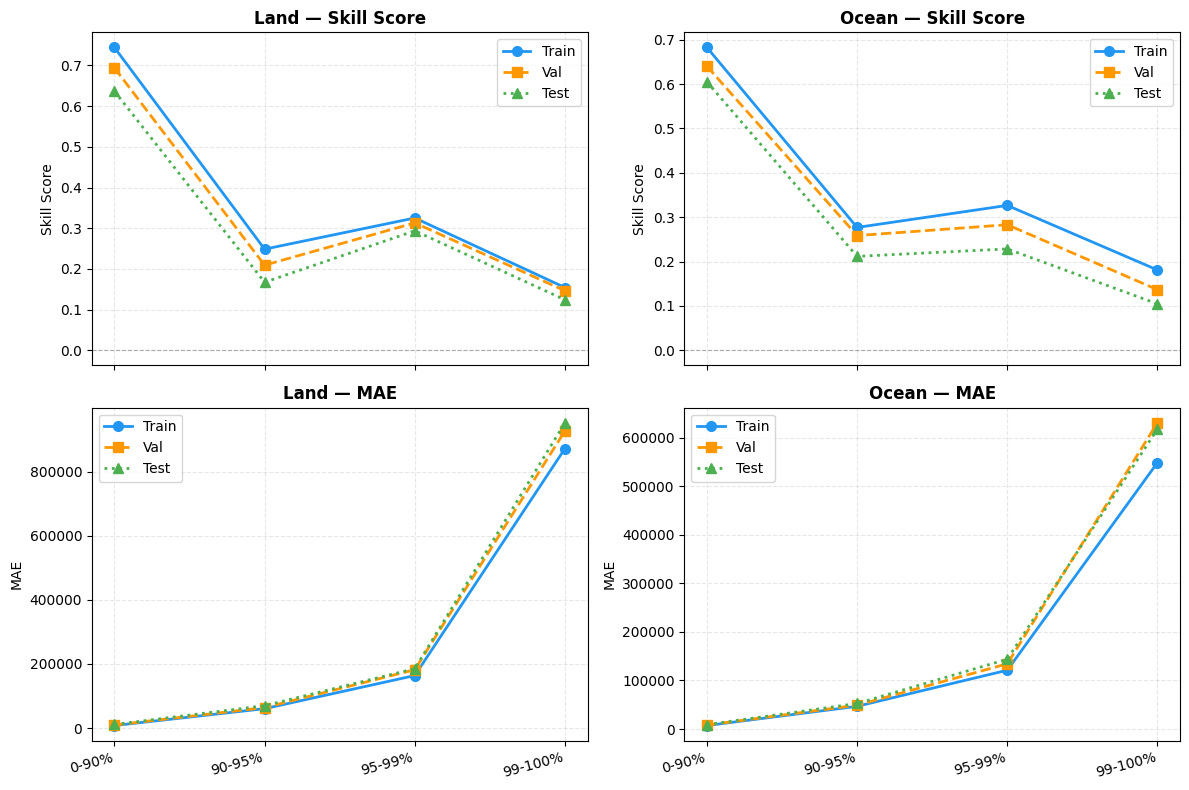

In [6]:
tag	= "land"
fname_land = f"results_{tag}.pkl"
metrics_land = joblib.load(metrics_dir + fname_land)
skill_train_land_0_90 = metrics_land["real_space"]["Train"]["regimes"]["0-90%"]["skill"]
mae_train_land_0_90 = metrics_land["real_space"]["Train"]["regimes"]["0-90%"]["mae_model"]
skill_val_land_0_90 = metrics_land["real_space"]["Val"]["regimes"]["0-90%"]["skill"]
mae_val_land_0_90 = metrics_land["real_space"]["Val"]["regimes"]["0-90%"]["mae_model"]
skill_test_land_0_90 = metrics_land["real_space"]["Test"]["regimes"]["0-90%"]["skill"]
mae_test_land_0_90 = metrics_land["real_space"]["Test"]["regimes"]["0-90%"]["mae_model"]
skill_train_land_90_95 = metrics_land["real_space"]["Train"]["regimes"]["90-95%"]["skill"]
mae_train_land_90_95 = metrics_land["real_space"]["Train"]["regimes"]["90-95%"]["mae_model"]
skill_val_land_90_95 = metrics_land["real_space"]["Val"]["regimes"]["90-95%"]["skill"]
mae_val_land_90_95 = metrics_land["real_space"]["Val"]["regimes"]["90-95%"]["mae_model"]
skill_test_land_90_95 = metrics_land["real_space"]["Test"]["regimes"]["90-95%"]["skill"]
mae_test_land_90_95 =	metrics_land["real_space"]["Test"]["regimes"]["90-95%"]["mae_model"]
skill_train_land_95_99 = metrics_land["real_space"]["Train"]["regimes"]["95-99%"]["skill"]
mae_train_land_95_99 = metrics_land["real_space"]["Train"]["regimes"]["95-99%"]["mae_model"]
skill_val_land_95_99 = metrics_land["real_space"]["Val"]["regimes"]["95-99%"]["skill"]
mae_val_land_95_99 = metrics_land["real_space"]["Val"]["regimes"]["95-99%"]["mae_model"]
skill_test_land_95_99 = metrics_land["real_space"]["Test"]["regimes"]["95-99%"]["skill"]
mae_test_land_95_99 =	metrics_land["real_space"]["Test"]["regimes"]["95-99%"]["mae_model"]
skill_train_land_99_100 = metrics_land["real_space"]["Train"]["regimes"]["99-100%"]["skill"]
mae_train_land_99_100 = metrics_land["real_space"]["Train"]["regimes"]["99-100%"]["mae_model"]
skill_val_land_99_100 = metrics_land["real_space"]["Val"]["regimes"]["99-100%"]["skill"]
mae_val_land_99_100 = metrics_land["real_space"]["Val"]["regimes"]["99-100%"]["mae_model"]
skill_test_land_99_100 = metrics_land["real_space"]["Test"]["regimes"]["99-100%"]["skill"]
mae_test_land_99_100 =	metrics_land["real_space"]["Test"]["regimes"]["99-100%"]["mae_model"]

tag	= "ocean"
fname_ocean = f"results_{tag}.pkl"
metrics_ocean = joblib.load(metrics_dir + fname_ocean)
skill_train_ocean_0_90 = metrics_ocean["real_space"]["Train"]["regimes"]["0-90%"]["skill"]
mae_train_ocean_0_90 = metrics_ocean["real_space"]["Train"]["regimes"]["0-90%"]["mae_model"]
skill_val_ocean_0_90 = metrics_ocean["real_space"]["Val"]["regimes"]["0-90%"]["skill"]
mae_val_ocean_0_90 = metrics_ocean["real_space"]["Val"]["regimes"]["0-90%"]["mae_model"]
skill_test_ocean_0_90	= metrics_ocean["real_space"]["Test"]["regimes"]["0-90%"]["skill"]
mae_test_ocean_0_90 = metrics_ocean["real_space"]["Test"]["regimes"]["0-90%"]["mae_model"]
skill_train_ocean_90_95 = metrics_ocean["real_space"]["Train"]["regimes"]["90-95%"]["skill"]
mae_train_ocean_90_95 = metrics_ocean["real_space"]["Train"]["regimes"]["90-95%"]["mae_model"]
skill_val_ocean_90_95 = metrics_ocean["real_space"]["Val"]["regimes"]["90-95%"]["skill"]
mae_val_ocean_90_95 = metrics_ocean["real_space"]["Val"]["regimes"]["90-95%"]["mae_model"]
skill_test_ocean_90_95	= metrics_ocean["real_space"]["Test"]["regimes"]["90-95%"]["skill"]
mae_test_ocean_90_95 = metrics_ocean["real_space"]["Test"]["regimes"]["90-95%"]["mae_model"]
skill_train_ocean_95_99 = metrics_ocean["real_space"]["Train"]["regimes"]["95-99%"]["skill"]
mae_train_ocean_95_99 = metrics_ocean["real_space"]["Train"]["regimes"]["95-99%"]["mae_model"]
skill_val_ocean_95_99 = metrics_ocean["real_space"]["Val"]["regimes"]["95-99%"]["skill"]
mae_val_ocean_95_99 = metrics_ocean["real_space"]["Val"]["regimes"]["95-99%"]["mae_model"]
skill_test_ocean_95_99	= metrics_ocean["real_space"]["Test"]["regimes"]["95-99%"]["skill"]
mae_test_ocean_95_99 = metrics_ocean["real_space"]["Test"]["regimes"]["95-99%"]["mae_model"]
skill_train_ocean_99_100	= metrics_ocean["real_space"]["Train"]["regimes"]["99-100%"]["skill"]

mae_train_ocean_99_100 = metrics_ocean["real_space"]["Train"]["regimes"]["99-100%"]["mae_model"]
skill_val_ocean_99_100 = metrics_ocean["real_space"]["Val"]["regimes"]["99-100%"]["skill"]
mae_val_ocean_99_100 = metrics_ocean["real_space"]["Val"]["regimes"]["99-100%"]["mae_model"]
skill_test_ocean_99_100 = metrics_ocean["real_space"]["Test"]["regimes"]["99-100%"]["skill"]
mae_test_ocean_99_100 = metrics_ocean["real_space"]["Test"]["regimes"]["99-100%"]["mae_model"]


import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np

# ── data ──────────────────────────────────────────────────────────────────────
regimes = ["0-90%", "90-95%", "95-99%", "99-100%"]
x = np.arange(len(regimes))

data = {
    "land": {
        "skill": {
            "Train": [skill_train_land_0_90, skill_train_land_90_95, skill_train_land_95_99, skill_train_land_99_100],
            "Val":   [skill_val_land_0_90,   skill_val_land_90_95,   skill_val_land_95_99,   skill_val_land_99_100],
            "Test":  [skill_test_land_0_90,  skill_test_land_90_95,  skill_test_land_95_99,  skill_test_land_99_100],
        },
        "mae": {
            "Train": [mae_train_land_0_90, mae_train_land_90_95, mae_train_land_95_99, mae_train_land_99_100],
            "Val":   [mae_val_land_0_90,   mae_val_land_90_95,   mae_val_land_95_99,   mae_val_land_99_100],
            "Test":  [mae_test_land_0_90,  mae_test_land_90_95,  mae_test_land_95_99,  mae_test_land_99_100],
        },
    },
    "ocean": {
        "skill": {
            "Train": [skill_train_ocean_0_90, skill_train_ocean_90_95, skill_train_ocean_95_99, skill_train_ocean_99_100],
            "Val":   [skill_val_ocean_0_90,   skill_val_ocean_90_95,   skill_val_ocean_95_99,   skill_val_ocean_99_100],
            "Test":  [skill_test_ocean_0_90,  skill_test_ocean_90_95,  skill_test_ocean_95_99,  skill_test_ocean_99_100],
        },
        "mae": {
            "Train": [mae_train_ocean_0_90, mae_train_ocean_90_95, mae_train_ocean_95_99, mae_train_ocean_99_100],
            "Val":   [mae_val_ocean_0_90,   mae_val_ocean_90_95,   mae_val_ocean_95_99,   mae_val_ocean_99_100],
            "Test":  [mae_test_ocean_0_90,  mae_test_ocean_90_95,  mae_test_ocean_95_99,  mae_test_ocean_99_100],
        },
    },
}

# ── style ─────────────────────────────────────────────────────────────────────
split_styles = {
    "Train": dict(color="#2196F3", ls="-",  marker="o"),
    "Val":   dict(color="#FF9800", ls="--", marker="s"),
    "Test":  dict(color="#4CAF50", ls=":",  marker="^"),
}
tag_titles = {"land": "Land", "ocean": "Ocean"}
metric_labels = {"skill": "Skill Score", "mae": "MAE"}

# ── plot ──────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)

for col, tag in enumerate(["land", "ocean"]):
    for row, metric in enumerate(["skill", "mae"]):
        ax = axes[row][col]

        for split, style in split_styles.items():
            ax.plot(
                x, data[tag][metric][split],
                label=split,
                color=style["color"],
                linestyle=style["ls"],
                marker=style["marker"],
                linewidth=2,
                markersize=7,
            )

        ax.set_title(f"{tag_titles[tag]} — {metric_labels[metric]}", fontweight="bold")
        ax.set_xticks(x)
        ax.set_xticklabels(regimes, rotation=15, ha="right")
        ax.set_ylabel(metric_labels[metric])
        ax.grid(True, alpha=0.3, linestyle="--")
        ax.legend(framealpha=0.8)

        # reference line at 0 for skill
        if metric == "skill":
            ax.axhline(0, color="gray", lw=0.8, ls="--", alpha=0.6)

plt.tight_layout()
plt.savefig(plots_dir + "regime_performance.png", dpi=150, bbox_inches="tight")
plt.show()

### 5.3 Explainable AI Analysis
To investigate which atmospheric variables control the neural-network predictions, a SHAP analysis was performed using Kernel SHAP. SHAP values were computed for 200 randomly selected samples from the independent test dataset and averaged across all output dimensions.

Figure X shows the resulting global feature importance ranking for the ocean model. The zonal wind component $u$ emerges as the dominant predictor, followed by meridional wind $v$, temperature $T$, meridional temperature gradient $\partial T/\partial y$, buoyancy $b$, and pressure $p$. Variables associated with horizontal gradients and vertical velocity exhibit substantially lower importance.

The dominance of wind and temperature-related variables is physically consistent with the generation of gravity waves by large-scale dynamical systems such as jets and fronts. In particular, the importance of meridional temperature gradients suggests that baroclinic structures play a significant role in determining the emitted gravity-wave spectrum.
The vertical distribution of SHAP values reveals that the model primarily relies on upper-level atmospheric information. The strongest contribution originates from zonal wind at approximately 15 km altitude, followed by meridional wind at the same level. Temperature exhibits a maximum importance near 11 km altitude, while buoyancy and static stability contribute across a broader vertical range.

Overall, the SHAP analysis indicates that the neural network extracts most of its predictive information from upper-tropospheric and lower-stratospheric flow structures, consistent with the known role of jet dynamics and frontal systems in generating gravity waves.

For the land model, the global SHAP ranking shows a similar dominance of resolved dynamical and thermodynamic variables. The zonal wind component $u$ is again the most important predictor, followed by static stability $N$, buoyancy $b$, temperature $T$, pressure $p$, and meridional wind $v$. In contrast, the additional subgrid-scale orographic descriptors have comparatively small SHAP values. The most important orographic features are the anisotropy ratio $\bar{k}/\bar{l}$, the total orographic spectral amplitude $\sum H$, and the zonal spectral width $\sigma_k^2$, but their contributions remain much smaller than those of the resolved atmospheric variables.

The vertical SHAP structure further indicates that the model relies primarily on upper-level flow information. The largest contribution comes from zonal wind at 15.1 km, followed by static stability and buoyancy in the upper troposphere and lower stratosphere. This behavior is physically consistent with the role of upper-level jets, stability structure, and background flow filtering in controlling gravity-wave emission and propagation.

The relatively small contribution of static orographic features suggests that, for the coarse-grained wave-action density considered here, the instantaneous resolved atmospheric state provides most of the predictive information. Orographic descriptors still contribute over land, but mainly as secondary modifiers of the flow-dependent response rather than as the dominant source of predictive skill.

shape of best mean : (90,)


/tmp/ipykernel_3651207/446375010.py:74: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(fontsize=11)


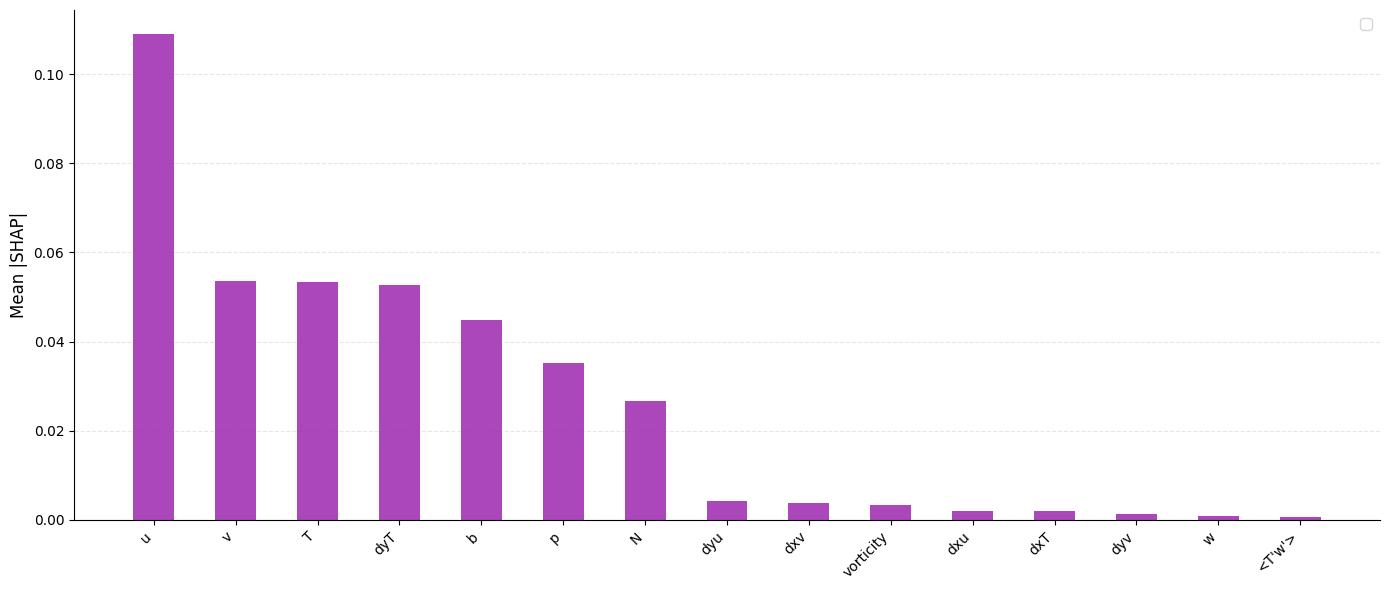

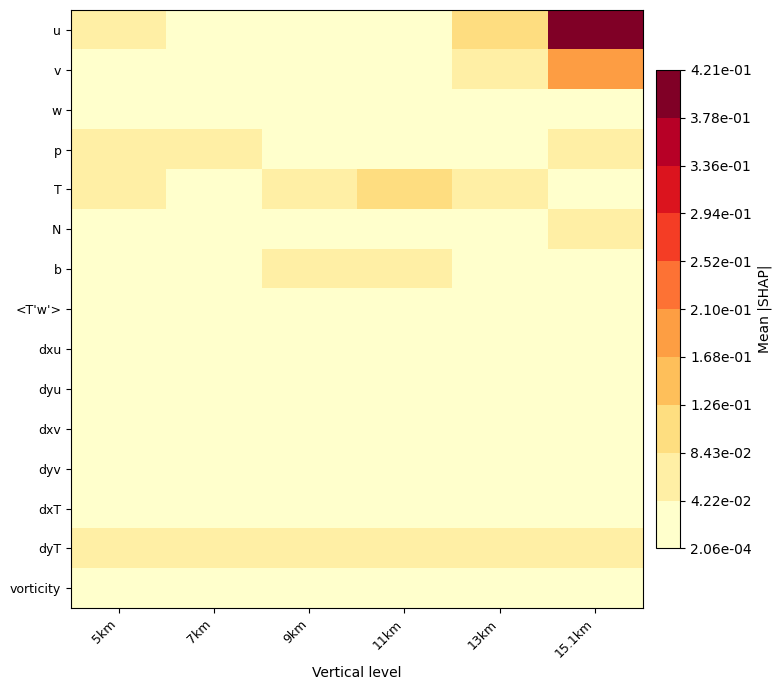

shape of best mean : (99,)


/tmp/ipykernel_3651207/446375010.py:74: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(fontsize=11)


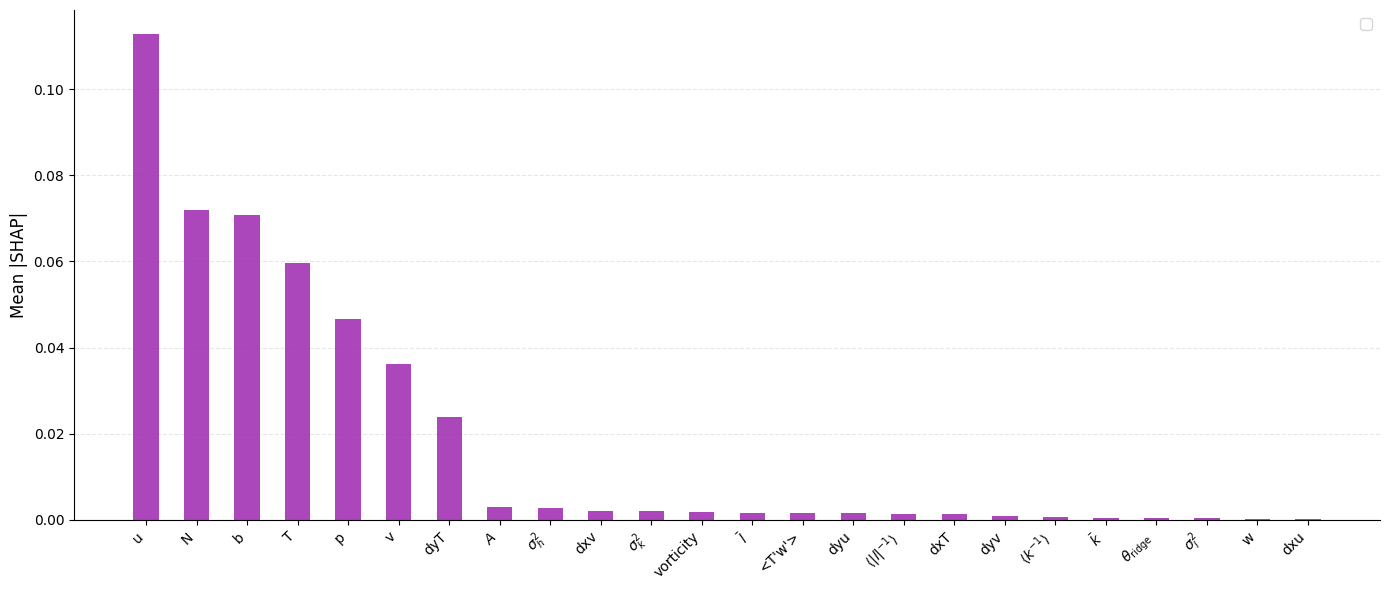

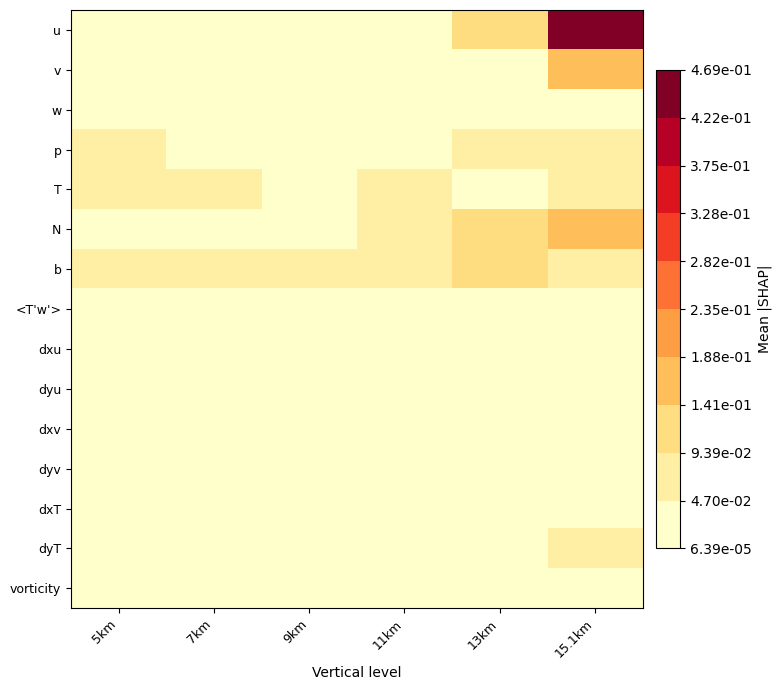

In [8]:
import joblib
import xarray as xr
import numpy as np
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

shap_dir = "/work/bb1097/b383521/ML_models/coarsed_grained/shap/"
for tag in ["ocean", "land"]:
				n_levels = 6
				sv_global  = np.load(shap_dir + f"svglobal_{tag}.npy")

				if sv_global.ndim == 3:
												sv_global  = np.mean(np.abs(sv_global),  axis=2)
				else:
												sv_global  = np.abs(sv_global)

				mean_global  = np.mean(sv_global,  axis=0) 
				print(f"shape of best mean : {mean_global.shape}")

				levels_labels  = ["15.1km", "13km", "11km", "9km", "7km", "5km"]      # L1 → L6
				levels_display = levels_labels[::-1]                                  # ascending: 5km → 15.1km

				base_vars = ["u", "v", "w", "p", "T", "N", "b", "<T'w'>",
																	"dxu", "dyu", "dxv", "dyv", "dxT", "dyT", "vorticity"]

				if tag == "land":
								orographic_feature_names = [
												r"$\sigma_h^2$",                  # 0 — total spectral power (topographic variance)
												r"$\bar{k}$",                     # 1 — spectral-weighted mean zonal wavenumber
												r"$\bar{l}$",                     # 2 — spectral-weighted mean meridional wavenumber (signed)
												r"$\langle k^{-1}\rangle$",       # 3 — effective zonal ridge scale
												r"$\langle |l|^{-1}\rangle$",     # 4 — effective meridional ridge scale
												r"$\sigma^2_k$",                  # 5 — zonal spectral width (variance)
												r"$\sigma^2_l$",                  # 6 — meridional spectral width (variance)
												r"$A$",                           # 7 — anisotropy
												r"$\theta_{\mathrm{ridge}}$",     # 8 — ridge orientation angle
								]
								group_names = np.array(base_vars + orographic_feature_names)  # ← concatenate then convert
				else:
												group_names = np.array(base_vars)                              # ← always numpy array
												

				group_global = []
				for i in range(len(base_vars)):
												sl = slice(i * n_levels, i * n_levels + n_levels)
												group_global.append(mean_global[sl].mean())

				if tag == "land":
											for i in range(len(orographic_feature_names)):
																group_global.append(mean_global[90+i])
																
				group_global   = np.array(group_global)
				sort_idx     = np.argsort(group_global)[::-1]

				### build vertical profile
				# atmospheric: (n_vars, n_levels)
				shap_matrix_global  = np.zeros((len(base_vars), n_levels))

				for i in range(len(base_vars)):
												sl = slice(i * n_levels, i * n_levels + n_levels)
												shap_matrix_global[i,  :] = mean_global[sl]
												
				import matplotlib.colors as mcolors

				# ── Fig 1: Variable importance ──────────────────────────────────────────
				fig, ax = plt.subplots(figsize=(14, 6))
				x = np.arange(len(group_names))
				w = 0.5

				ax.bar(x, group_global[sort_idx], width=w, color="#9C27B0", alpha=0.85)
				ax.set_xticks(x)
				ax.set_xticklabels(group_names[sort_idx], rotation=45, ha="right", fontsize=10)
				ax.set_ylabel("Mean |SHAP|", fontsize=12)
				ax.legend(fontsize=11)
				ax.spines[["top", "right"]].set_visible(False)
				ax.yaxis.grid(True, alpha=0.3, linestyle="--")
				ax.set_axisbelow(True)
				plt.tight_layout()
				plt.savefig(plots_dir + f"Shape_{tag}_all.png")
				plt.show()

				# ── Fig 2: Variable × Level heatmap ─────────────────────────────────────
				mat_global_flip = shap_matrix_global[:, ::-1]   # flip: 5km → 15.1km left→right

				n_bins = 10
				bounds = np.linspace(mat_global_flip.min(), mat_global_flip.max(), n_bins + 1)
				norm   = mcolors.BoundaryNorm(boundaries=bounds, ncolors=256)

				fig, ax = plt.subplots(figsize=(8, 7))
				im = ax.imshow(mat_global_flip, aspect="auto", cmap="YlOrRd", norm=norm)
				ax.set_xticks(range(n_levels))
				ax.set_xticklabels(levels_display, rotation=45, ha="right", fontsize=9)
				ax.set_yticks(range(len(base_vars)))
				ax.set_yticklabels(base_vars, fontsize=9)
				ax.set_xlabel("Vertical level")
				cbar = fig.colorbar(im, ax=ax, label="Mean |SHAP|",
																								shrink=0.8, pad=0.02, ticks=bounds)
				cbar.ax.yaxis.set_major_formatter(
								plt.FuncFormatter(lambda x, _: f"{x:.2e}"))
				plt.tight_layout()
				plt.savefig(plots_dir + f"Shape_{tag}_flow.png")
				plt.show()

